In [27]:
import shutil
shutil.copy(
    "/kaggle/input/datasets/adityapratapparmar/patrolling-sim/patrolling_sim.py",
    "/kaggle/working/patrolling_sim.py"
)

'/kaggle/working/patrolling_sim.py'

In [28]:
import numpy as np

def build_grid_graph(rows, cols):
    """
    Builds a grid graph where each node is connected to its 4 direct neighbors (up, down, left, right).
    Nodes are indexed from 0 to rows*cols - 1.
    """
    n_nodes = rows * cols
    neighbors = [[] for _ in range(n_nodes)]
    for i in range(rows):
        for j in range(cols):
            node_idx = i * cols + j
            # Up
            if i > 0:
                neighbors[node_idx].append((i - 1) * cols + j)
            # Down
            if i < rows - 1:
                neighbors[node_idx].append((i + 1) * cols + j)
            # Left
            if j > 0:
                neighbors[node_idx].append(i * cols + (j - 1))
            # Right
            if j < cols - 1:
                neighbors[node_idx].append(i * cols + (j + 1))
    return neighbors


class Robot:
    def __init__(self, initial_position, rng):
        self.position = initial_position
        self.rng = rng

    def choose_next(self, neighbors, idleness, forbidden=None):
        current_neighbors = neighbors[self.position]
        if forbidden is not None:
            filtered = [n for n in current_neighbors if n != forbidden]
            if filtered:
                current_neighbors = filtered
        if len(current_neighbors) == 0:
            return self.position
        nbrs = np.array(current_neighbors)
        vals = idleness[nbrs]
        max_idle = vals.max()
        candidates = nbrs[vals == max_idle]
        return int(self.rng.choice(candidates))


class CoordinatedHIFSimulator:
    def __init__(self, seed=42, idleness_init=None, robot1_pos=0, robot2_pos=99, neighbors_override=None):
        self.rng = np.random.default_rng(seed)
        self.rows, self.cols = 10, 10
        self.n_nodes = 100
        self.neighbors = neighbors_override if neighbors_override is not None else build_grid_graph(self.rows, self.cols)

        if idleness_init is None:
            self.idleness = np.zeros(self.n_nodes, dtype=np.int32)
        else:
            self.idleness = idleness_init.astype(np.int32).copy()

        self.robot1 = Robot(robot1_pos, self.rng)
        self.robot2 = Robot(robot2_pos, self.rng)

    def step(self):
        self.idleness += 1
        next1 = self.robot1.choose_next(self.neighbors, self.idleness)
        next2 = self.robot2.choose_next(self.neighbors, self.idleness, forbidden=next1)
        self.robot1.position = next1
        self.robot2.position = next2
        self.idleness[next1] = 0
        self.idleness[next2] = 0
        return self.idleness.mean(), self.idleness.max()

In [29]:
import numpy as np
from tqdm import tqdm


def generate_one_example(rng, n_nodes=100, total_steps=1_000_000, 
                          tail_start=900_000, neighbors_override=None):
    r1_pos, r2_pos = rng.choice(n_nodes, size=2, replace=False)
    initial_idleness = np.zeros(n_nodes, dtype=np.int32)

    sim = CoordinatedHIFSimulator(
        seed=int(rng.integers(0, 2**31 - 1)),
        idleness_init=initial_idleness,
        robot1_pos=int(r1_pos),
        robot2_pos=int(r2_pos),
        neighbors_override=neighbors_override
    )

    max_iai = -np.inf
    max_maxidle = -np.inf
    X_row = None

    for t in range(total_steps):
        iai, max_idle = sim.step()

        if t == tail_start:
            idle_snapshot = sim.idleness.astype(np.float32).copy()
            r1_onehot = np.zeros(n_nodes, dtype=np.float32)
            r2_onehot = np.zeros(n_nodes, dtype=np.float32)
            r1_onehot[sim.robot1.position] = 1.0
            r2_onehot[sim.robot2.position] = 1.0
            X_row = np.concatenate([idle_snapshot, r1_onehot, r2_onehot])

        if t >= tail_start:
            if iai > max_iai:
                max_iai = iai
            if max_idle > max_maxidle:
                max_maxidle = max_idle

    Y_row = np.array([max_iai, max_maxidle], dtype=np.float32)
    return X_row, Y_row

In [ ]:
import numpy as np
import os
from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm import tqdm
from patrolling_sim import run_single_simulation

N_RUNS = 10_000
TOTAL_STEPS = 1_000_000
TAIL_START = 900_000

# Step 1: Regenerate the FULL config list (same seed = same list, always)
rng = np.random.default_rng(43)
run_configs = []
for i in range(N_RUNS):
    r1_pos, r2_pos = rng.choice(100, size=2, replace=False)
    seed = int(rng.integers(0, 2**31 - 1))
    run_configs.append((seed, int(r1_pos), int(r2_pos), TOTAL_STEPS, TAIL_START, None))

# Step 2: Load your uploaded checkpoint
CHECKPOINT_INPUT = "/kaggle/input/datasets/adityapratapparmar/partial-10000run-checkpoint4/partial_10000run_checkpoint.npz"
CHECKPOINT_OUTPUT = "/kaggle/working/partial_10000run_checkpoint.npz"

ckpt = np.load(CHECKPOINT_INPUT)
X_data = ckpt["X_data"].copy()
Y_data = ckpt["Y_data"].copy()
start_from = int(ckpt["completed"])
print(f"Resuming from run {start_from} / {N_RUNS}")

done_mask = np.zeros(N_RUNS, dtype=bool)
done_mask[:start_from] = True  # mark previously completed runs

# Step 3: Only submit configs for runs NOT already done
remaining_indices = list(range(start_from, N_RUNS))
print(f"Runs remaining: {len(remaining_indices)}")

N_WORKERS = 4  # Kaggle CPU-only max

if __name__ == "__main__":
    with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = {executor.submit(run_single_simulation, run_configs[i]): i for i in remaining_indices}
        completed_since_checkpoint = 0
        for future in tqdm(as_completed(futures), total=len(remaining_indices)):
            i = futures[future]
            X_row, Y_row = future.result()
            X_data[i] = X_row
            Y_data[i] = Y_row
            done_mask[i] = True
            completed_since_checkpoint += 1
            if completed_since_checkpoint % 50 == 0:
                np.savez_compressed(CHECKPOINT_OUTPUT, X_data=X_data, Y_data=Y_data,
                                     done_mask=done_mask, completed=int(done_mask.sum()))

    np.savez_compressed(CHECKPOINT_OUTPUT, X_data=X_data, Y_data=Y_data,
                         done_mask=done_mask, completed=int(done_mask.sum()))

    if done_mask.all():
        np.savez_compressed("/kaggle/working/full_10000run_dataset.npz", X_data=X_data, Y_data=Y_data)
        print("All runs complete. Final dataset saved.")
    else:
        print(f"Session ended with {done_mask.sum()}/{N_RUNS} done. Re-run to resume.")

In [30]:
import numpy as np

d = np.load("/kaggle/input/datasets/adityapratapparmar/full-10000-run/full_10000run_dataset.npz")
X_data = d["X_data"]
Y_data = d["Y_data"]
print("X_data:", X_data.shape, "Y_data:", Y_data.shape)

X_data: (10000, 300) Y_data: (10000, 2)


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_temp, Y_train, Y_temp = train_test_split(X_data, Y_data, test_size=0.2, random_state=1)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=2)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (8000, 300) Val: (1000, 300) Test: (1000, 300)


In [33]:
# Idleness block (cols 0:100) — now contains the REAL idleness state at t=900,000,
# not all zeros. This is the actual fix Arpita asked for.
mean = X_train[:, :100].mean(axis=0)
std = X_train[:, :100].std(axis=0)
std[std < 1e-6] = 1.0
X_train[:, :100] = (X_train[:, :100] - mean) / std
X_val[:, :100]   = (X_val[:, :100]   - mean) / std
X_test[:, :100]  = (X_test[:, :100]  - mean) / std

# Targets — log-transform first (heavy tail, same as before), then z-score
Y_train_log = np.log1p(Y_train)
Y_val_log   = np.log1p(Y_val)
Y_test_log  = np.log1p(Y_test)

y_mean = Y_train_log.mean(axis=0)
y_std  = Y_train_log.std(axis=0)
y_std[y_std < 1e-6] = 1.0

Y_train_n = (Y_train_log - y_mean) / y_std
Y_val_n   = (Y_val_log   - y_mean) / y_std
Y_test_n  = (Y_test_log  - y_mean) / y_std

In [34]:
import torch
import torch.nn as nn
class PatrollingMLP(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(300, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2)
        )
    def forward(self, x):
        return self.net(x)

Using device: cpu
PatrollingMLP(
  (net): Sequential(
    (0): Linear(in_features=300, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)
Epoch 001/100 | LR 0.000500 | Train 0.406348 | Val 0.411180
Epoch 002/100 | LR 0.000500 | Train 0.393610 | Val 0.398157
Epoch 003/100 | LR 0.000500 | Train 0.370273 | Val 0.363133
Epoch 004/100 | LR 0.000500 | Train 0.316964 | Val 0.288042
Epoch 005/100 | LR 0.000500 | Train 0.252572 | Val 0.222711
Epoch 006/100 | LR 0.000500 | Train 0.222142 | Val 0.212114
Epoch 007/100 | LR 0.000500 | Train 0.210466 | Val 0.206639
Epoch 008/100 | LR 0.000500 | Train 0.202024 | Val 0.204869
Epoch 009/100 | LR 0.000500 | Train 0.196984 | Val 0.199714
Epoch 010/100 | LR 0.000500 | Train 0.187683 | Val 0.201757
Epoch 011/100 | LR 0.000500 | Train 0.185487 | V

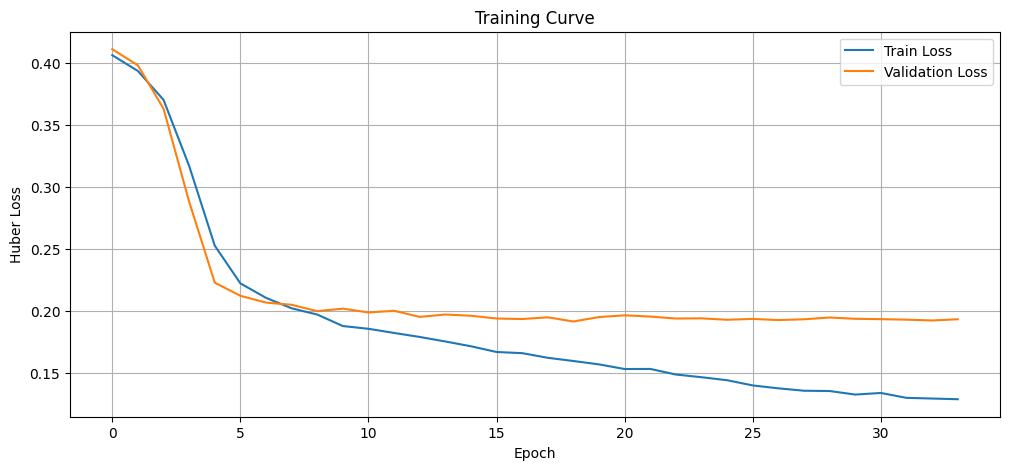

In [35]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

class PatrollingDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

train_dataset = PatrollingDataset(X_train, Y_train_n)
val_dataset   = PatrollingDataset(X_val,   Y_val_n)
test_dataset  = PatrollingDataset(X_test,  Y_test_n)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=256, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)

# NOTE: no class definition here anymore — uses PatrollingMLP from Cell 7 (128→64)
model = PatrollingMLP(dropout=0.2).to(DEVICE)
print(model)

criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

EPOCHS = 100
EARLY_STOPPING_PATIENCE = 15
best_val_loss = float("inf")
early_stop_counter = 0
train_losses, val_losses = [], []

for epoch in range(EPOCHS):
    model.train()
    running_train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()
        preds = model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running_train_loss += loss.item() * X_batch.size(0)
    train_loss = running_train_loss / len(train_loader.dataset)

    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            running_val_loss += loss.item() * X_batch.size(0)
    val_loss = running_val_loss / len(val_loader.dataset)

    scheduler.step(val_loss)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch+1:03d}/{EPOCHS} | LR {current_lr:.6f} | Train {train_loss:.6f} | Val {val_loss:.6f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pt")
        early_stop_counter = 0
    else:
        early_stop_counter += 1

    if early_stop_counter >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

model.load_state_dict(torch.load("best_model.pt", map_location=DEVICE))
print("\nTraining Complete")
print("Best Validation Loss:", best_val_loss)

plt.figure(figsize=(12,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Huber Loss"); plt.title("Training Curve")
plt.legend(); plt.grid(True); plt.show()

In [36]:
import numpy as np
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(DEVICE)
        preds = model(X_batch)
        all_preds.append(preds.cpu().numpy())
        all_targets.append(y_batch.numpy())

preds_log = np.vstack(all_preds) * y_std + y_mean
targets_log = np.vstack(all_targets) * y_std + y_mean

preds = np.expm1(preds_log)
targets = np.expm1(targets_log)

true_iai, pred_iai = targets[:, 0], preds[:, 0]
true_maxidle, pred_maxidle = targets[:, 1], preds[:, 1]

print("\n== FUTURE MAX IAI ==")
print(f"MAE  : {mean_absolute_error(true_iai, pred_iai):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(true_iai, pred_iai)):.4f}")
print(f"R²   : {r2_score(true_iai, pred_iai):.4f}")

print("\n== FUTURE MAX MAXIDLE ==")
print(f"MAE  : {mean_absolute_error(true_maxidle, pred_maxidle):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(true_maxidle, pred_maxidle)):.4f}")
print(f"R²   : {r2_score(true_maxidle, pred_maxidle):.4f}")


== FUTURE MAX IAI ==
MAE  : 0.2849
RMSE : 0.3710
R²   : 0.7116

== FUTURE MAX MAXIDLE ==
MAE  : 1.6700
RMSE : 2.1973
R²   : 0.4899


In [37]:
spike_like = true_maxidle > np.percentile(true_maxidle, 75)
print("R² non-spike-like:", r2_score(true_maxidle[~spike_like], pred_maxidle[~spike_like]))
print("R² spike-like:    ", r2_score(true_maxidle[spike_like], pred_maxidle[spike_like]))
print("MAE non-spike-like:", mean_absolute_error(true_maxidle[~spike_like], pred_maxidle[~spike_like]))
print("MAE spike-like:    ", mean_absolute_error(true_maxidle[spike_like], pred_maxidle[spike_like]))

R² non-spike-like: -0.1865919828414917
R² spike-like:     -0.8998454809188843
MAE non-spike-like: 1.1678680181503296
MAE spike-like:     3.4816153049468994
